# Лабораторная работа №4
## Деревья решений и ансамбли

**Курс:** Основы машинного обучения  
**Цель:** Реализовать решающее дерево вручную и выяснить, за счёт чего ансамбли деревьев обобщают лучше одиночного дерева  
**Дедлайн:** см. таблицу учёта успеваемости

---

### Инструкция по выполнению

1. **Вариант:** укажите свой `Student_ID` в задании 0.1 — он определит датасет и параметры задания
2. **Именование переменных:** строго соблюдайте указанные имена — они используются для автопроверки
3. **Функции:** реализуйте каждую функцию с указанной сигнатурой; не меняйте имена функций и параметров
4. **Визуализации:** все графики должны иметь заголовок и подписи осей
5. **Сохранение:** перед сдачей выполните `Kernel → Restart & Run All` и убедитесь, что ошибок нет

---
## Блок 0: Настройка варианта

### Задание 0.1: Укажите свой Student_ID

Найдите свой порядковый номер (поле «№ п/п») в таблице учёта успеваемости курса и укажите его ниже.

In [42]:
Student_ID = 14  # Укажите свой порядковый номер, например: Student_ID = 7

### Задание 0.2: Определение варианта

Выполните ячейку ниже — она определит ваш датасет и параметры задания.

In [43]:
# (dataset_name, uci_id, target_col, positive_class, description)
# dataset_name   — короткое название датасета
# uci_id         — идентификатор датасета в репозитории UCI ML Repository
# target_col     — название целевой переменной
# positive_class — значение целевой переменной, которое соответствует классу 1
#                  (для wine_quality — порог: класс 1, если quality >= 7)
# description    — полное название датасета и источник для загрузки
datasets = [
    (
        'spambase',
        94,
        'Class',
        1,
        'Spambase (UCI id=94): является ли письмо спамом, '
        'https://archive.ics.uci.edu/dataset/94/spambase'
    ),
    (
        'magic_gamma',
        159,
        'class',
        'g',
        'MAGIC Gamma Telescope (UCI id=159): гамма-квант (g) или адронный фон (h), '
        'https://archive.ics.uci.edu/dataset/159/magic+gamma+telescope'
    ),
    (
        'rice',
        545,
        'Class',
        'Cammeo',
        'Rice (Cammeo and Osmancik) (UCI id=545): сорт риса по форме зерна, '
        'https://archive.ics.uci.edu/dataset/545/rice+cammeo+and+osmancik'
    ),
    (
        'german_credit',
        144,
        'class',
        2,
        'Statlog German Credit (UCI id=144): кредитный риск заёмщика (2 — плохой), '
        'https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data'
    ),
    (
        'wine_quality',
        186,
        'quality',
        7,
        'Wine Quality (UCI id=186): высокое качество вина (quality >= 7), '
        'https://archive.ics.uci.edu/dataset/186/wine+quality'
    ),
    (
        'breast_cancer',
        17,
        'Diagnosis',
        'M',
        'Breast Cancer Wisconsin Diagnostic (UCI id=17): злокачественная опухоль (M), '
        'https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic'
    ),
]

if Student_ID is None:
    print("ОШИБКА! Не указан Student_ID. Вернитесь к заданию 0.1.")
else:
    dataset_id = (Student_ID - 1) % len(datasets)
    DATASET_NAME, UCI_ID, TARGET_COL, POSITIVE_CLASS, DATASET_DESC = datasets[dataset_id]

    print(f"Ваш вариант: датасет №{dataset_id + 1}")
    print(f"Датасет:     {DATASET_DESC}")
    print(f"Целевая переменная: {TARGET_COL}")
    if DATASET_NAME == 'wine_quality':
        print(f"Класс 1:     {TARGET_COL} >= {POSITIVE_CLASS}")
    else:
        print(f"Класс 1:     {TARGET_COL} == {POSITIVE_CLASS!r}")

Ваш вариант: датасет №2
Датасет:     MAGIC Gamma Telescope (UCI id=159): гамма-квант (g) или адронный фон (h), https://archive.ics.uci.edu/dataset/159/magic+gamma+telescope
Целевая переменная: class
Класс 1:     class == 'g'


### Задание 0.3: Установка зависимостей

In [ ]:
# Установка необходимых библиотек (выполните один раз)
# !pip install ucimlrepo
# !pip install xgboost catboost  # используется в бонусном задании 5.3

In [1]:
import time
from typing import Any, Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.figure

from ucimlrepo import fetch_ucirepo
from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Библиотеки загружены.")

Matplotlib is building the font cache; this may take a moment.


Библиотеки загружены.


---
## Блок 1: Данные

**Максимум: 10 баллов**

### Задание 1.1 — Загрузка и подготовка данных (6 баллов)

Загрузите датасет с помощью `fetch_ucirepo(id=UCI_ID)` и подготовьте:

- `X` — `pd.DataFrame` с признаками. Все столбцы числовые, пропусков (`NaN`) нет. Категориальные признаки закодируйте целыми числами, например `OrdinalEncoder`.
- `y` — `pd.Series` из 0 и 1 той же длины, что `X`. Класс 1 — объекты, у которых целевая переменная равна `POSITIVE_CLASS`. Для варианта `wine_quality` класс 1 — объекты с `quality >= POSITIVE_CLASS`.

Масштабировать признаки не нужно. Объясните в `prep_comment`:
- почему решающему дереву не нужна стандартизация признаков;
- почему порядковое кодирование категорий подходит для дерева и хуже подходит для линейной модели.

> 💡 **Подсказка:** `fetch_ucirepo(...)` возвращает объект с полями `.data.features` и `.data.targets`. Нечисловые столбцы удобно найти через `DataFrame.select_dtypes(exclude='number')`.

In [13]:
# TODO: загрузите датасет через fetch_ucirepo(id=UCI_ID)
# TODO: сформируйте матрицу признаков (только числовые столбцы, без NaN)
df = fetch_ucirepo(id=159)
X: pd.DataFrame = df.data.features.copy()  # размерность (n, d)

# TODO: сформируйте целевую переменную из 0 и 1
y: pd.Series = (df.data.targets['class'] == 'g').astype(int)  # размерность (n,)

duplicates = pd.concat([X, y], axis=1).duplicated()
X = X.loc[~duplicates]
y = y.loc[~duplicates]


# TODO: ответьте на вопросы задания
prep_comment: str = (f"""Удалил {duplicates.sum()} полных повторов по признакам и классу до разбиения. 
    Это исключает попадание копий одной записи одновременно в обучение и тест. 
    В этом датасете все признаки числовые. Проверка показала 0 пропусков. 
    Стандартизация сохраняет порядок значений, поэтому дерево может получить 
    те же разбиения, выбрав пороги в новом масштабе. 
    Дерево может выделять категории по их кодам несколькими разбиениями. 
    Линейная модель считает разницу во вкладе между соседними кодами одинаковой, 
    хотя порядок категорий может быть условным.""")  # «Стандартизация не нужна, потому что ...; порядковое кодирование ...»

### Задание 1.2 — Разделение на выборки (4 балла)

Разделите `X`, `y` на обучающую и тестовую выборки функцией `train_test_split`:
- доля тестовой выборки — 25% (`test_size=0.25`);
- стратификация по целевой переменной (`stratify=y`);
- `random_state=RANDOM_STATE`.

Гиперпараметры в блоках 3–4 подбираются кросс-валидацией на обучающей выборке, поэтому отдельная валидационная выборка не нужна.

In [14]:
# TODO: разделите X, y на обучающую и тестовую выборки
split = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

X_train: pd.DataFrame = split[0]  # размерность (n_train, d)
X_test:  pd.DataFrame = split[1]  # размерность (n_test, d)
y_train: pd.Series = split[2]     # размерность (n_train,)
y_test:  pd.Series = split[3]     # размерность (n_test,)

if all(v is not None for v in [X_train, X_test]):
    print(f"Train: {len(X_train)}, доля класса 1: {y_train.mean():.3f}")
    print(f"Test:  {len(X_test)}, доля класса 1: {y_test.mean():.3f}")

Train: 14178, доля класса 1: 0.652
Test:  4727, доля класса 1: 0.652


---
## Блок 2: Решающее дерево вручную

**Максимум: 36 баллов**

В заданиях 2.1–2.3 **запрещено** использовать `sklearn.tree` и другие готовые реализации деревьев. Используйте только `numpy` и `pandas`. В задании 2.4 вы сравните своё дерево с `DecisionTreeClassifier`.

Во всех заданиях блока метки классов — 0 и 1.

### Задание 2.1 — Критерии неоднородности (6 баллов)

Пусть $p_k$ — доля объектов класса $k$ в узле. Индекс Джини и энтропия:

$$
G(y) = 1 - \sum_k p_k^2, \qquad H(y) = -\sum_k p_k \log_2 p_k.
$$

Слагаемое энтропии при $p_k = 0$ считается равным нулю. Для пустого вектора меток обе функции возвращают 0.

Реализуйте `gini_impurity` и `entropy_impurity`.

In [20]:
def gini_impurity(y: np.ndarray) -> float:
    '''Индекс Джини для вектора меток.

    Параметры:
        y — вектор меток классов, размерность (n,)

    Возвращает:
        float — значение индекса Джини, 0 для чистого узла
    '''
    # TODO: ваш код
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    p = counts / len(y)
    return float(1 - np.sum(p ** 2))



def entropy_impurity(y: np.ndarray) -> float:
    '''Энтропия (по основанию 2) для вектора меток.

    Параметры:
        y — вектор меток классов, размерность (n,)

    Возвращает:
        float — значение энтропии, 0 для чистого узла
    '''
    # TODO: ваш код
    if len(y) == 0:
        return 0.0
    
    _, counts = np.unique(y, return_counts=True)
    p = counts / len(y)
    return float(-np.sum(p * np.log2(p)))

### Задание 2.2 — Поиск лучшего разбиения (10 баллов)

Разбиение узла задаётся признаком $j$ и порогом $t$: объект идёт в левую часть, если $x_j \le t$, иначе — в правую. Качество разбиения — прирост информации (information gain):

$$
\text{Gain}(j, t) = I(y) - \left(\frac{n_L}{n}\, I(y_L) + \frac{n_R}{n}\, I(y_R)\right),
$$

где $I$ — `gini_impurity` при `criterion="gini"` и `entropy_impurity` при `criterion="entropy"`, $n_L$ и $n_R$ — число объектов в левой и правой частях.

Реализуйте функцию `best_split`, которая перебирает все признаки и пороги и возвращает разбиение с наибольшим приростом информации.

**Требования:**
- кандидаты в пороги — середины между соседними различными значениями признака после сортировки;
- разбиения с пустой частью не рассматриваются;
- если разбить узел нельзя (все признаки постоянны), функция возвращает `(None, None, 0.0)`.

> 💡 **Подсказка:** перебор порогов с пересчётом неоднородности на каждом шаге требует $O(n^2)$ операций на признак — на датасете из десятков тысяч объектов это слишком долго. После сортировки по признаку число объектов класса 1 в левой части для всех порогов сразу даёт `np.cumsum`, а доли классов слева и справа вычисляются векторно.

In [21]:
def best_split(
    X: np.ndarray,
    y: np.ndarray,
    criterion: str = "gini"
) -> Tuple[Optional[int], Optional[float], float]:
    '''Поиск разбиения с наибольшим приростом информации.

    Параметры:
        X         — матрица признаков, размерность (n, d)
        y         — вектор меток из 0 и 1, размерность (n,)
        criterion — "gini" или "entropy"

    Возвращает:
        Кортеж (feature_idx, threshold, gain):
        feature_idx — индекс признака (int), threshold — порог (float),
        gain — прирост информации (float);
        (None, None, 0.0), если разбиение невозможно
    '''
    # TODO: ваш код
    n = len(y)
    if n < 2:
        return None, None, 0.0

    impurity = {"gini": gini_impurity, "entropy": entropy_impurity}[criterion]
    parent_impurity = impurity(y)
    total_ones = y.sum()

    def binary_impurity(p):
        if criterion == "gini":
            return 2 * p * (1 - p)

        entropy = np.zeros_like(p)
        mixed = (p > 0) & (p < 1)
        q = p[mixed]
        entropy[mixed] = -q * np.log2(q) - (1 - q) * np.log2(1 - q)
        return entropy

    best_feature = None
    best_threshold = None
    best_gain = 0.0

    for j in range(X.shape[1]):
        order = np.argsort(X[:, j])
        values = X[order, j]
        cuts = np.flatnonzero(values[:-1] < values[1:])
        if len(cuts) == 0:
            continue

        n_left = cuts + 1
        n_right = n - n_left
        ones_left = np.cumsum(y[order])[cuts]
        ones_right = total_ones - ones_left

        left_impurity = binary_impurity(ones_left / n_left)
        right_impurity = binary_impurity(ones_right / n_right)
        gains = parent_impurity - (n_left * left_impurity + n_right * right_impurity) / n

        i = int(np.argmax(gains))
        gain = max(0.0, float(gains[i]))
        if best_feature is None or gain > best_gain:
            cut = cuts[i]
            best_feature = j
            best_threshold = float(values[cut] / 2 + values[cut + 1] / 2)
            best_gain = gain

    return best_feature, best_threshold, best_gain


### Задание 2.3 — Класс DecisionTreeManual (14 баллов)

Реализуйте бинарное решающее дерево, которое строится рекурсивно с помощью `best_split`.

Узел становится листом, если выполнено хотя бы одно условие:
- достигнута глубина `max_depth` (корень имеет глубину 0; `None` — без ограничения);
- в узле меньше `min_samples_split` объектов;
- все объекты узла одного класса;
- `best_split` не нашёл разбиения.

Лист хранит долю объектов класса 1 среди попавших в него обучающих объектов — это оценка вероятности класса 1. Метод `predict` возвращает 1, если эта вероятность больше 0.5, иначе 0.

Способ хранения узлов выберите сами (словари, вложенный класс и т. п.).

In [22]:
class DecisionTreeManual:
    '''Решающее дерево для бинарной классификации.

    Параметры:
        max_depth         — максимальная глубина дерева (None — без ограничения)
        min_samples_split — минимальное число объектов в узле для его разбиения
        criterion         — критерий неоднородности: "gini" или "entropy"
    '''

    def __init__(
        self,
        max_depth: Optional[int] = None,
        min_samples_split: int = 2,
        criterion: str = "gini"
    ) -> None:
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.criterion = criterion

    def fit(self, X: np.ndarray, y: np.ndarray) -> "DecisionTreeManual":
        '''Построение дерева по обучающей выборке.

        Параметры:
            X — матрица признаков, размерность (n, d)
            y — вектор меток из 0 и 1, размерность (n,)

        Возвращает:
            self
        '''
        # TODO: ваш код
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        def build(X_node, y_node, depth):
            p = float(y_node.mean())
            depth_limit = self.max_depth is not None and depth >= self.max_depth

            if (
                depth_limit
                or len(y_node) < self.min_samples_split
                or p in (0.0, 1.0)
            ):
                return {"probability": p}

            feature, threshold, _ = best_split(X_node, y_node, self.criterion)
            if feature is None:
                return {"probability": p}

            left = X_node[:, feature] <= threshold
            return {
                "feature": feature,
                "threshold": threshold,
                "left": build(X_node[left], y_node[left], depth + 1),
                "right": build(X_node[~left], y_node[~left], depth + 1),
            }

        self.tree_ = build(X, y, 0)
        return self


    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        '''Оценки вероятностей классов.

        Параметры:
            X — матрица признаков, размерность (n, d)

        Возвращает:
            np.ndarray размерности (n, 2) — вероятности классов 0 и 1;
            сумма по строкам равна 1
        '''
        # TODO: ваш код
        X = np.asarray(X, dtype=float)
        p1 = np.empty(len(X))

        for i, row in enumerate(X):
            node = self.tree_
            while "feature" in node:
                if row[node["feature"]] <= node["threshold"]:
                    node = node["left"]
                else:
                    node = node["right"]

            p1[i] = node["probability"]

        return np.column_stack((1 - p1, p1))

    def predict(self, X: np.ndarray) -> np.ndarray:
        '''Предсказание меток классов.

        Параметры:
            X — матрица признаков, размерность (n, d)

        Возвращает:
            np.ndarray размерности (n,) из 0 и 1
        '''
        # TODO: ваш код
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)

### Задание 2.4 — Сравнение с DecisionTreeClassifier (6 баллов)

Обучите на `X_train`, `y_train` два дерева с одинаковыми гиперпараметрами:
- `tree_manual` — `DecisionTreeManual(max_depth=4)`;
- `tree_sklearn` — `DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)`.

Запишите в `manual_vs_sklearn_agreement` долю объектов тестовой выборки, на которых предсказания двух деревьев совпадают.

> 💡 **Подсказка:** при правильной реализации предсказания почти полностью совпадают. Если согласие заметно ниже 0.95, проверьте, по какую сторону от порога попадает объект с $x_j = t$ и как выбираются кандидаты в пороги.

In [23]:
# TODO: обучите собственное дерево
tree_manual: DecisionTreeManual = DecisionTreeManual(max_depth=4).fit(X_train, y_train)

# TODO: обучите дерево из sklearn с теми же гиперпараметрами
tree_sklearn: DecisionTreeClassifier = DecisionTreeClassifier(
    max_depth=4, random_state=RANDOM_STATE
).fit(X_train, y_train)

# TODO: доля совпадающих предсказаний на X_test
manual_vs_sklearn_agreement: float = float(
    np.mean(tree_manual.predict(X_test) == tree_sklearn.predict(X_test))
)   # значение в [0, 1]
manual_vs_sklearn_agreement

1.0

---
## Блок 3: Переобучение решающего дерева

**Максимум: 20 баллов**

Начиная с этого блока используйте `DecisionTreeClassifier` из `sklearn`.

### Задание 3.1 — Зависимость качества от глубины (8 баллов)

Для каждого значения `max_depth` от 1 до 20 обучите `DecisionTreeClassifier(max_depth=..., random_state=RANDOM_STATE)` и вычислите:
- `train_accuracy` — долю верных ответов на обучающей выборке после обучения на всей `X_train`;
- `cv_accuracy` — среднюю долю верных ответов на 5-кратной кросс-валидации по `X_train` (`cross_val_score` с `cv=5`).

Сохраните результат в `depth_scores` — `pd.DataFrame` со столбцами `max_depth`, `train_accuracy`, `cv_accuracy` (20 строк).

Реализуйте функцию `plot_depth_curve`, которая рисует обе кривые на одних осях, и сохраните график в `fig_depth`.

В `depth_comment` ответьте:
- при какой глубине качество на кросс-валидации максимально;
- с какой глубины начинается переобучение и по каким признакам на графике это видно;
- почему доля верных ответов на обучающей выборке с ростом глубины приближается к 1.

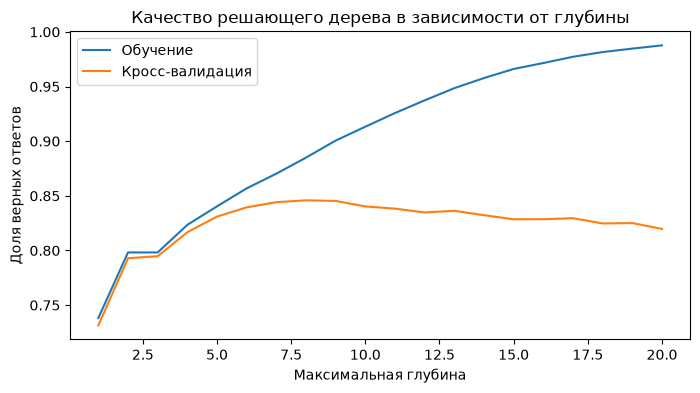

In [ ]:
def plot_depth_curve(depth_scores: pd.DataFrame) -> matplotlib.figure.Figure:
    '''Кривые качества решающего дерева в зависимости от глубины.

    Параметры:
        depth_scores — таблица со столбцами max_depth, train_accuracy, cv_accuracy

    Возвращает:
        matplotlib.figure.Figure с двумя кривыми на одних осях
    '''
    # TODO: ваш код
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(depth_scores["max_depth"], depth_scores["train_accuracy"], label="Обучение")
    ax.plot(depth_scores["max_depth"], depth_scores["cv_accuracy"], label="Кросс-валидация")
    ax.set_title("Качество решающего дерева в зависимости от глубины")
    ax.set_xlabel("Максимальная глубина")
    ax.set_ylabel("Доля верных ответов")
    ax.legend()
    return fig


# TODO: вычислите качество для max_depth от 1 до 20

rows = []
for depth in range(1, 21):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    tree.fit(X_train, y_train)
    train_accuracy = tree.score(X_train, y_train)
    cv_accuracy = cross_val_score(tree, X_train, y_train, cv=5).mean()
    rows.append((depth, train_accuracy, cv_accuracy))

depth_scores: pd.DataFrame = pd.DataFrame(
    rows, columns=["max_depth", "train_accuracy", "cv_accuracy"]
)  # 20 строк, столбцы max_depth, train_accuracy, cv_accuracy

# TODO: постройте график
fig_depth: matplotlib.figure.Figure = plot_depth_curve(depth_scores)

# TODO: интерпретируйте результаты

depth_comment: str = ("""Максимальная точность на кросс-валидации 0.846 при глубине 8. 
С глубины 9 виден признак переобучения. По сравнению с лучшей глубиной точность на обучении выше, на CV ниже. 
Чем глубже дерево, тем на более мелкие группы оно делит данные. Оно может подстроиться под отдельные обучающие объекты, 
поэтому точность на обучении приближается к 1."""
)   # «Максимум на кросс-валидации при глубине ...; переобучение начинается ...»

### Задание 3.2 — Подбор гиперпараметров дерева (7 баллов)

Подберите гиперпараметры `DecisionTreeClassifier(random_state=RANDOM_STATE)` с помощью `GridSearchCV` (5-кратная кросс-валидация, метрика — доля верных ответов) по сетке:

| Гиперпараметр | Значения |
|---|---|
| `max_depth` | 3, 5, 8, 12, `None` |
| `min_samples_leaf` | 1, 5, 20 |
| `ccp_alpha` | 0.0, 0.001, 0.01 |

`ccp_alpha` — коэффициент стрижки (cost-complexity pruning): чем он больше, тем сильнее обрезается дерево после построения.

Сохраните лучшую модель в `best_tree` (обученную на всей `X_train`), лучшие значения гиперпараметров — в `best_tree_params` (словарь).

> 💡 **Подсказка:** у обученного `GridSearchCV` есть атрибуты `best_estimator_` и `best_params_`. Параметр `n_jobs=-1` ускоряет перебор.

In [27]:
# TODO: подберите гиперпараметры решающего дерева
param_grid = {
    "max_depth": [3, 5, 8, 12, None],
    "min_samples_leaf": [1, 5, 20],
    "ccp_alpha": [0.0, 0.001, 0.01],
}
tree_search = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
)
tree_search.fit(X_train, y_train)
best_tree: DecisionTreeClassifier = tree_search.best_estimator_

# TODO: сохраните лучшие значения гиперпараметров
best_tree_params: Dict[str, Any] = tree_search.best_params_  # ключи max_depth, min_samples_leaf, ccp_alpha
best_tree_params

{'ccp_alpha': 0.0, 'max_depth': 8, 'min_samples_leaf': 1}

### Задание 3.3 — Визуализация дерева (5 баллов)

Реализуйте функцию `plot_tree_top`, которая рисует верхние `depth` уровней обученного дерева с помощью `sklearn.tree.plot_tree` (параметр `max_depth`). Подпишите узлы именами признаков и задайте заголовок фигуры.

Сохраните в `fig_tree` изображение верхних трёх уровней `best_tree`.

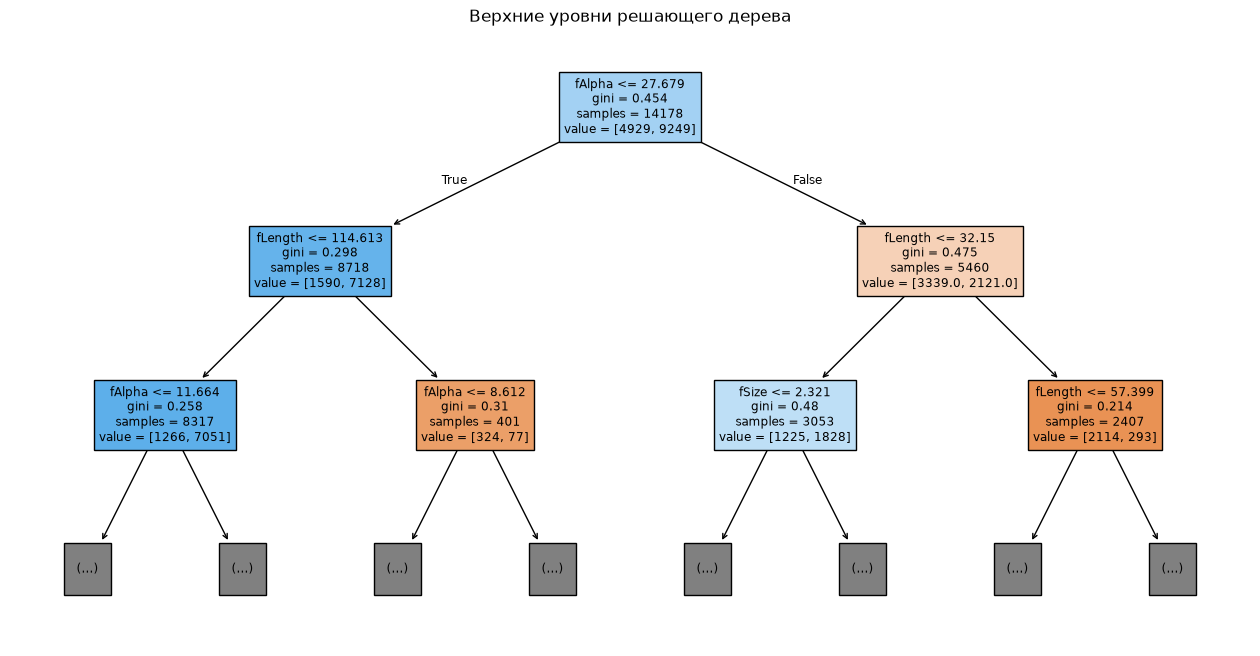

In [28]:
def plot_tree_top(
    model: DecisionTreeClassifier,
    feature_names: List[str],
    depth: int = 3
) -> matplotlib.figure.Figure:
    '''Изображение верхних уровней решающего дерева.

    Параметры:
        model         — обученный DecisionTreeClassifier
        feature_names — имена признаков в порядке столбцов X
        depth         — число отображаемых уровней

    Возвращает:
        matplotlib.figure.Figure с изображением дерева
    '''
    # TODO: ваш код
    fig, ax = plt.subplots(figsize=(16, 8))
    plot_tree(
        model,
        max_depth=depth - 1,
        feature_names=feature_names,
        filled=True,
        ax=ax,
    )
    ax.set_title("Верхние уровни решающего дерева")
    return fig


# TODO: нарисуйте верхние три уровня best_tree
fig_tree: matplotlib.figure.Figure = plot_tree_top(best_tree, list(X_train.columns), depth=3)

---
## Блок 4: Ансамбли деревьев

**Максимум: 34 балла**

Все модели блока обучайте на `X_train`, `y_train` с `random_state=RANDOM_STATE`.

### Задание 4.1 — Бэггинг (5 баллов)

Бэггинг (bagging) обучает каждое дерево на бутстреп-выборке — выборке того же размера, взятой из обучающей с возвращением. Около трети объектов не попадает в бутстреп-выборку конкретного дерева. Предсказания деревьев на таких объектах дают оценку качества без отдельной выборки — out-of-bag (OOB) оценку.

Обучите `BaggingClassifier` над решающими деревьями без ограничения глубины: `estimator=DecisionTreeClassifier()`, `n_estimators=100`, `oob_score=True`. Сохраните модель в `bagging`, OOB-оценку доли верных ответов — в `bagging_oob`.

In [29]:
# TODO: обучите бэггинг над решающими деревьями
bagging: BaggingClassifier = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    oob_score=True,
    random_state=RANDOM_STATE,
).fit(X_train, y_train)

# TODO: сохраните OOB-оценку
bagging_oob: float = float(bagging.oob_score_)  # значение в [0, 1]

### Задание 4.2 — Случайный лес (7 баллов)

Случайный лес (random forest) — бэггинг деревьев, в котором при каждом разбиении узла рассматривается случайное подмножество признаков. Это делает деревья менее похожими друг на друга.

1. Для `n_estimators` из списка `[10, 25, 50, 100, 200]` обучите `RandomForestClassifier(oob_score=True)` и сохраните OOB-оценки в словарь `rf_curve` вида `{n_estimators: oob_score}`.
2. Реализуйте функцию `plot_n_estimators_curve` и сохраните график зависимости OOB-оценки от числа деревьев в `fig_rf`.
3. Сохраните в `rf` случайный лес из 200 деревьев.

c:\Users\Rick\Desktop\ITMO\3_kurs\ML\LR4\example\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


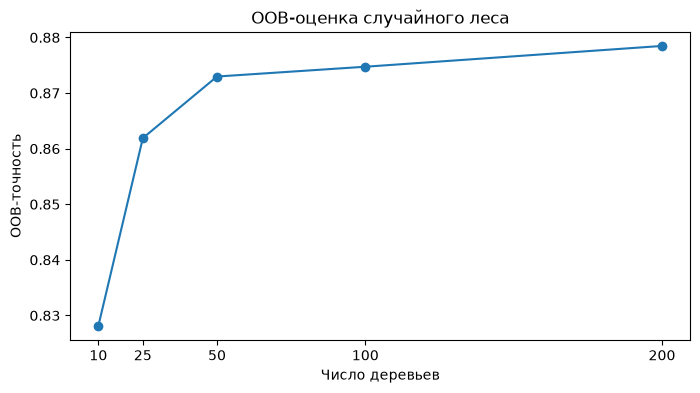

In [34]:
def plot_n_estimators_curve(rf_curve: Dict[int, float]) -> matplotlib.figure.Figure:
    '''Зависимость OOB-оценки случайного леса от числа деревьев.

    Параметры:
        rf_curve — словарь {n_estimators: OOB-оценка доли верных ответов}

    Возвращает:
        matplotlib.figure.Figure
    '''
    # TODO: ваш код
    n_trees = sorted(rf_curve)
    scores = [rf_curve[n] for n in n_trees]

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(n_trees, scores, marker="o")
    ax.set_title("OOB-оценка случайного леса")
    ax.set_xlabel("Число деревьев")
    ax.set_ylabel("OOB-точность")
    ax.set_xticks(n_trees)
    return fig


# TODO: вычислите OOB-оценки для разного числа деревьев
rf_curve: Dict[int, float] = {}  # ключи 10, 25, 50, 100, 200
for n_estimators in [10, 25, 50, 100, 200]:
    forest = RandomForestClassifier(
        n_estimators=n_estimators,
        oob_score=True,
        random_state=RANDOM_STATE,
    ).fit(X_train, y_train)
    rf_curve[n_estimators] = float(forest.oob_score_)
# TODO: постройте график
fig_rf: matplotlib.figure.Figure = plot_n_estimators_curve(rf_curve)

# TODO: обучите случайный лес из 200 деревьев
rf: RandomForestClassifier = forest

### Задание 4.3 — Градиентный бустинг (8 баллов)

Градиентный бустинг (gradient boosting) строит деревья последовательно: каждое следующее дерево исправляет ошибки суммы предыдущих. Вклад каждого дерева умножается на темп обучения `learning_rate`.

1. Обучите два `GradientBoostingClassifier(n_estimators=200, max_depth=3)` с `learning_rate=0.1` и `learning_rate=0.5`. Модель с `learning_rate=0.1` сохраните в `gb`.
2. Метод `staged_predict` возвращает предсказания ансамбля после добавления каждого дерева. Вычислите для обеих моделей долю ошибок на тестовой выборке после 1, 2, …, 200 деревьев и сохраните в словарь `gb_test_errors` вида `{learning_rate: np.ndarray}`.
3. Постройте обе кривые на одном графике `fig_gb_staged`.
4. В `gb_best_n_estimators` запишите число деревьев, при котором ошибка модели с `learning_rate=0.1` минимальна (при нескольких минимумах — наименьшее).

Здесь кривая на тестовой выборке служит иллюстрацией. Для выбора числа деревьев на практике используют валидационную выборку или кросс-валидацию.

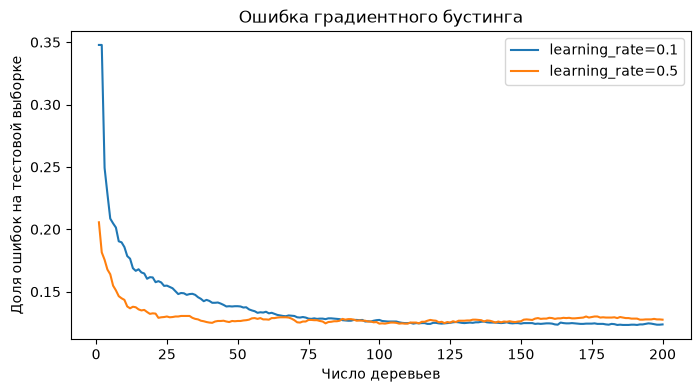

In [30]:
# TODO: обучите градиентный бустинг с learning_rate=0.1
gb_models = {}
for rate in [0.1, 0.5]:
    gb_models[rate] = GradientBoostingClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=rate,
        random_state=RANDOM_STATE,
    ).fit(X_train, y_train)
gb: GradientBoostingClassifier = gb_models[0.1]

# TODO: доли ошибок на тестовой выборке после каждого дерева для обоих learning_rate
gb_test_errors: Dict[float, np.ndarray] = {}  # ключи 0.1 и 0.5, массивы размерности (200,)
for rate, model in gb_models.items():
    gb_test_errors[rate] = np.array([
        1 - accuracy_score(y_test, predictions)
        for predictions in model.staged_predict(X_test)
    ])

# TODO: постройте кривые ошибки
fig_gb_staged: matplotlib.figure.Figure = plt.figure(figsize=(8, 4))
ax = fig_gb_staged.add_subplot()
for rate, errors in gb_test_errors.items():
    ax.plot(range(1, 201), errors, label=f"learning_rate={rate}")

ax.set_title("Ошибка градиентного бустинга")
ax.set_xlabel("Число деревьев")
ax.set_ylabel("Доля ошибок на тестовой выборке")
ax.legend()


# TODO: число деревьев с минимальной ошибкой для learning_rate=0.1
gb_best_n_estimators: int = int(np.argmin(gb_test_errors[0.1])) + 1

### Задание 4.4 — AdaBoost и HistGradientBoosting (5 баллов)

1. AdaBoost перевзвешивает объекты: после каждого шага растёт вес объектов, на которых ансамбль ошибается. Обучите `AdaBoostClassifier` над решающими пнями — деревьями глубины 1 (`estimator=DecisionTreeClassifier(max_depth=1)`), `n_estimators=200`. Сохраните модель в `ada`.
2. `HistGradientBoostingClassifier` — градиентный бустинг, который перед обучением разбивает значения признаков на интервалы (гистограммы). За счёт этого он обучается быстрее `GradientBoostingClassifier` на больших выборках. Обучите его с параметрами по умолчанию и сохраните в `hgb`.

In [32]:
# TODO: обучите AdaBoost над решающими пнями
ada: AdaBoostClassifier = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=200,
    random_state=RANDOM_STATE,
).fit(X_train, y_train)


# TODO: обучите HistGradientBoostingClassifier
hgb: HistGradientBoostingClassifier = HistGradientBoostingClassifier(
    random_state=RANDOM_STATE
).fit(X_train, y_train)

### Задание 4.5 — Сводное сравнение моделей (9 баллов)

Реализуйте функцию `compare_models`, которая для каждой модели из словаря:
1. создаёт необученную копию модели (`sklearn.base.clone`) и обучает её на обучающей выборке, замеряя время обучения в секундах;
2. вычисляет на тестовой выборке Accuracy, F1 и ROC-AUC (для ROC-AUC нужны вероятности класса 1 из `predict_proba`).

Функция возвращает `pd.DataFrame`: строки — имена моделей, столбцы — `Accuracy`, `F1`, `ROC-AUC`, `fit_time`.

Вызовите функцию для шести моделей с именами `Tree` (`best_tree`), `Bagging`, `RandomForest`, `AdaBoost`, `GradBoost` (`gb`), `HistGB` и сохраните результат в `results_df`.

В `ensembles_comment` ответьте:
- какая модель лучшая по ROC-AUC и насколько ансамбли превосходят одиночное дерево;
- за счёт чего бэггинг и случайный лес снижают ошибку дерева, а за счёт чего — бустинг;
- чем приходится платить за прирост качества (время обучения, интерпретируемость).

> 💡 **Подсказка:** для замера времени используйте `time.perf_counter()` до и после вызова `fit`.

In [46]:
def compare_models(
    models: Dict[str, Any],
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    y_test: pd.Series
) -> pd.DataFrame:
    '''Сводная таблица качества и времени обучения моделей.

    Параметры:
        models  — словарь {имя_модели: модель sklearn}
        X_train — признаки обучающей выборки, размерность (n_train, d)
        y_train — метки обучающей выборки, размерность (n_train,)
        X_test  — признаки тестовой выборки, размерность (n_test, d)
        y_test  — метки тестовой выборки, размерность (n_test,)

    Возвращает:
        pd.DataFrame со строками по моделям и столбцами
        Accuracy, F1, ROC-AUC, fit_time
    '''
    # TODO: ваш код
    results = {}
    for name, model in models.items():
        fitted = clone(model)
        start = time.perf_counter()
        fitted.fit(X_train, y_train)
        fit_time = time.perf_counter() - start

        predictions = fitted.predict(X_test)
        probabilities = fitted.predict_proba(X_test)[:, 1]
        results[name] = {
            "Accuracy": accuracy_score(y_test, predictions),
            "F1": f1_score(y_test, predictions),
            "ROC-AUC": roc_auc_score(y_test, probabilities),
            "fit_time": fit_time,
        }

    return pd.DataFrame.from_dict(results, orient="index")


# TODO: вызовите compare_models для шести моделей
models = {
    "Tree": best_tree,
    "Bagging": bagging,
    "RandomForest": rf,
    "AdaBoost": ada,
    "GradBoost": gb,
    "HistGB": hgb,
}
results_df: pd.DataFrame = compare_models(
    models, X_train, y_train, X_test, y_test
)  # строки Tree, Bagging, RandomForest, AdaBoost, GradBoost, HistGB

# TODO: интерпретируйте результаты
auc = results_df["ROC-AUC"]
best_model = auc.idxmax()
tree_auc = auc["Tree"]
differences = auc.drop("Tree") - tree_auc
differences_text = ", ".join(f"{name} {delta:+.3f}" for name, delta in differences.items())

ensembles_comment: str = (
    f"""Модель {best_model} показала лучший ROC-AUC {auc[best_model]:.3f}. 
    У одиночного дерева ROC-AUC равен {tree_auc:.3f}. 
    Разница ROC-AUC относительно дерева — {differences_text}. 
    Бэггинг усредняет прогнозы деревьев, обученных на разных бутстреп-выборках, 
    и снижает разброс предсказаний. Случайный лес ещё и выбирает случайный набор 
    признаков в каждом узле, поэтому ошибки деревьев реже совпадают. 
    Бустинг добавляет деревья по очереди, стараясь уменьшить ошибку текущего ансамбля. 
    Дерево обучалось {results_df.loc['Tree', 'fit_time']:.3f} с, 
    случайный лес — {results_df.loc['RandomForest', 'fit_time']:.3f} с. 
    "Прогноз ансамбля сложнее объяснить, потому что он зависит от нескольких деревьев."""
)  # «Лучшая модель по ROC-AUC — ...; бэггинг снижает ...; бустинг снижает ...»
print(ensembles_comment)
results_df

Модель HistGB показала лучший ROC-AUC 0.934. 
    У одиночного дерева ROC-AUC равен 0.872. 
    Разница ROC-AUC относительно дерева — Bagging +0.052, RandomForest +0.060, AdaBoost +0.016, GradBoost +0.055, HistGB +0.063. 
    Бэггинг усредняет прогнозы деревьев, обученных на разных бутстреп-выборках, 
    и снижает разброс предсказаний. Случайный лес ещё и выбирает случайный набор 
    признаков в каждом узле, поэтому ошибки деревьев реже совпадают. 
    Бустинг добавляет деревья по очереди, стараясь уменьшить ошибку текущего ансамбля. 
    Дерево обучалось 0.246 с, 
    случайный лес — 16.972 с. 
    "Прогноз ансамбля сложнее объяснить, потому что он зависит от нескольких деревьев.


,Accuracy,F1,ROC-AUC,fit_time
Tree,0.845780,0.887448,0.871671,0.246092
Bagging,0.874127,0.906137,0.924136,25.414489
RandomForest,0.877512,0.908805,0.932145,16.972497
AdaBoost,0.840914,0.881910,0.887674,7.807707
GradBoost,0.876243,0.908722,0.926897,16.968462
HistGB,0.883012,0.913146,0.934409,0.598558


---
## Блок 5: Бонусные задания

**Максимум: 20 бонусных баллов**

Бонусные задания выполняются по желанию и не влияют на получение основных баллов.

> ⚠️ **Если вы не планируете выполнять бонусные задания:** удалите объявления функций и классов из этого блока, а переменным присвойте `None` или удалите их полностью. Незаполненные заглушки (`raise NotImplementedError`) вызовут ошибку при запуске тестов.

### ⭐ Задание 5.1 — Случайный лес вручную (7 бонусных баллов)

Реализуйте класс `RandomForestManual` поверх `DecisionTreeManual` из задания 2.3. Для каждого из `n_estimators` деревьев:
1. сформируйте бутстреп-выборку: `n` индексов объектов с возвращением;
2. выберите случайное подмножество признаков без возвращения: $\lfloor\sqrt{d}\rfloor$ признаков при `max_features="sqrt"`, все $d$ признаков при `max_features=None`;
3. обучите `DecisionTreeManual(max_depth=max_depth)` на выбранных объектах и признаках.

Сохраните деревья в атрибут `estimators_` (список `DecisionTreeManual`), индексы признаков каждого дерева — в `features_` (список массивов). `predict_proba` усредняет вероятности деревьев.

Здесь подмножество признаков выбирается один раз на дерево (метод случайных подпространств), а не при каждом разбиении узла, как в `RandomForestClassifier`.

Обучите `rf_manual = RandomForestManual(n_estimators=30, max_depth=6, random_state=RANDOM_STATE)` на `X_train`, `y_train`.

> 💡 **Подсказка:** для воспроизводимости используйте генератор `np.random.default_rng(random_state)`.

In [45]:
class RandomForestManual:
    '''Случайный лес из деревьев DecisionTreeManual.

    Атрибуты после обучения:
        estimators_ — список обученных DecisionTreeManual, длина n_estimators
        features_   — список массивов индексов признаков каждого дерева
    '''

    def __init__(
        self,
        n_estimators: int = 30,
        max_depth: Optional[int] = 6,
        max_features: Optional[str] = "sqrt",
        random_state: Optional[int] = None
    ) -> None:
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.max_features = max_features
        self.random_state = random_state

    def fit(self, X: np.ndarray, y: np.ndarray) -> "RandomForestManual":
        '''Обучение деревьев на бутстреп-выборках.

        Параметры:
            X — матрица признаков, размерность (n, d)
            y — вектор меток из 0 и 1, размерность (n,)

        Возвращает:
            self
        '''
        # TODO: ваш код
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        n, d = X.shape
        rng = np.random.default_rng(self.random_state)

        trees = []
        features = []
        for _ in range(self.n_estimators):
            rows = rng.choice(n, size=n, replace=True)
            if self.max_features == "sqrt":
                cols = rng.choice(d, size=int(np.sqrt(d)), replace=False)
            else:
                cols = np.arange(d)

            tree = DecisionTreeManual(max_depth=self.max_depth)
            tree.fit(X[rows][:, cols], y[rows])
            trees.append(tree)
            features.append(cols)

        self.estimators_ = trees
        self.features_ = features
        return self

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        '''Усреднённые вероятности классов по деревьям.

        Параметры:
            X — матрица признаков, размерность (n, d)

        Возвращает:
            np.ndarray размерности (n, 2)
        '''
        # TODO: ваш код
        X = np.asarray(X, dtype=float)
        probabilities = [
            tree.predict_proba(X[:, cols])
            for tree, cols in zip(self.estimators_, self.features_)
        ]
        return np.mean(probabilities, axis=0)

    def predict(self, X: np.ndarray) -> np.ndarray:
        '''Предсказание меток классов.

        Параметры:
            X — матрица признаков, размерность (n, d)

        Возвращает:
            np.ndarray размерности (n,) из 0 и 1
        '''
        # TODO: ваш код
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)

# TODO: обучите собственный случайный лес
rf_manual: RandomForestManual = RandomForestManual(
    n_estimators=30, max_depth=6, random_state=RANDOM_STATE
).fit(X_train, y_train)

### ⭐ Задание 5.2 — Градиентный бустинг вручную (7 бонусных баллов)

Реализуйте класс `GradientBoostingManual` для бинарной классификации с логистической функцией потерь. Модель — сумма деревьев в пространстве логитов:

$$
F_M(x) = F_0 + \eta \sum_{m=1}^{M} h_m(x), \qquad p(x) = \sigma(F_M(x)) = \frac{1}{1 + e^{-F_M(x)}}.
$$

1. Начальное приближение — логарифм отношения шансов на обучающей выборке: $F_0 = \ln\frac{\bar y}{1 - \bar y}$.
2. На шаге $m$ вычислите антиградиент логистической функции потерь по $F$ — псевдоостатки $r_i = y_i - \sigma(F_{m-1}(x_i))$.
3. Обучите `DecisionTreeRegressor(max_depth=max_depth)` на парах $(x_i, r_i)$ и добавьте его предсказания с множителем $\eta$ (`learning_rate`).
4. После каждого шага сохраняйте значение логистической функции потерь на обучающей выборке в атрибут `loss_history` (`np.ndarray` длины `n_estimators` после обучения).

Обучите `gb_manual = GradientBoostingManual(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE)` на `X_train`, `y_train` и постройте график `fig_gb_manual_loss` — значения `loss_history` по номеру дерева.

Text(0, 0.5, 'Логистическая функция потерь')

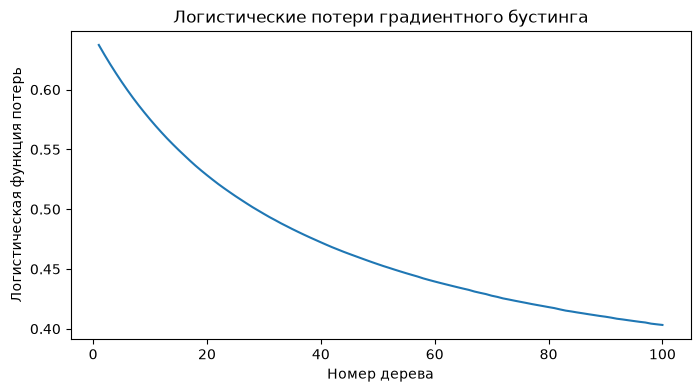

In [37]:
class GradientBoostingManual:
    '''Градиентный бустинг с логистической функцией потерь.

    Атрибуты после обучения:
        estimators_  — список обученных DecisionTreeRegressor
        loss_history — значения функции потерь на обучающей выборке
                       после каждого дерева, np.ndarray размерности (n_estimators,)
    '''

    def __init__(
        self,
        n_estimators: int = 100,
        learning_rate: float = 0.1,
        max_depth: int = 3,
        random_state: Optional[int] = None
    ) -> None:
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.random_state = random_state

    def fit(self, X: np.ndarray, y: np.ndarray) -> "GradientBoostingManual":
        '''Последовательное обучение деревьев на псевдоостатках.

        Параметры:
            X — матрица признаков, размерность (n, d)
            y — вектор меток из 0 и 1, размерность (n,)

        Возвращает:
            self
        '''
        # TODO: ваш код
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        p0 = np.clip(y.mean(), 1e-6, 1 - 1e-6)
        initial_logit = float(np.log(p0 / (1 - p0)))
        logits = np.full(len(y), initial_logit)
        trees = []
        losses = []

        for _ in range(self.n_estimators):
            p = 1 / (1 + np.exp(-np.clip(logits, -500, 500)))
            residuals = y - p

            tree = DecisionTreeRegressor(
                max_depth=self.max_depth, random_state=self.random_state
            ).fit(X, residuals)

            logits += self.learning_rate * tree.predict(X)
            trees.append(tree)
            losses.append(np.mean(np.logaddexp(0, logits) - y * logits))

        self.initial_logit_ = initial_logit
        self.estimators_ = trees
        self.loss_history = np.array(losses)
        return self

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        '''Вероятности классов.

        Параметры:
            X — матрица признаков, размерность (n, d)

        Возвращает:
            np.ndarray размерности (n, 2)
        '''
        # TODO: ваш код
        X = np.asarray(X, dtype=float)
        logits = np.full(len(X), self.initial_logit_)

        for tree in self.estimators_:
            logits += self.learning_rate * tree.predict(X)

        p = 1 / (1 + np.exp(-np.clip(logits, -500, 500)))
        return np.column_stack((1 - p, p))


# TODO: обучите собственный градиентный бустинг
gb_manual: GradientBoostingManual = GradientBoostingManual(
    n_estimators=100, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE
).fit(X_train, y_train)

# TODO: постройте график функции потерь по номеру дерева
fig_gb_manual_loss: matplotlib.figure.Figure = plt.figure(figsize=(8, 4))
ax = fig_gb_manual_loss.add_subplot()
ax.plot(range(1, len(gb_manual.loss_history) + 1), gb_manual.loss_history)
ax.set_title("Логистические потери градиентного бустинга")
ax.set_xlabel("Номер дерева")
ax.set_ylabel("Логистическая функция потерь")

### ⭐ Задание 5.3 — XGBoost или CatBoost (6 бонусных баллов)

Выберите одну из библиотек градиентного бустинга — XGBoost (`xgboost.XGBClassifier`) или CatBoost (`catboost.CatBoostClassifier`) — и обучите модель на `X_train`, `y_train`. Гиперпараметры подберите самостоятельно.

Сохраните обученную модель в `boost_lib_model`, ROC-AUC на тестовой выборке — в `boost_lib_auc`. Сравните результат с `HistGradientBoostingClassifier` из `results_df`.

> 💡 **Подсказка:** XGBoost не принимает имена признаков с символами `[`, `]` и `<`. Если в вашем датасете такие есть, переименуйте столбцы или передайте `X_train.values`. У CatBoost задайте `verbose=0`, чтобы не выводить журнал обучения.

In [39]:
from catboost import CatBoostClassifier

# TODO: обучите модель XGBoost или CatBoost
boost_lib_model: Any = CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.05,
    random_seed=RANDOM_STATE,
    verbose=0,
    allow_writing_files=False,
).fit(X_train, y_train)

# TODO: ROC-AUC на тестовой выборке
probabilities = boost_lib_model.predict_proba(X_test)[:, 1]
boost_lib_auc: float = float(roc_auc_score(y_test, probabilities))  # значение в [0, 1]

histgb_auc = results_df.loc["HistGB", "ROC-AUC"]
print(f"ROC-AUC CatBoost: {boost_lib_auc:.4f}")
print(f"ROC-AUC HistGB:   {histgb_auc:.4f}")
print(f"Разница с HistGB: {boost_lib_auc - histgb_auc:+.4f}")

ROC-AUC CatBoost: 0.9365
ROC-AUC HistGB:   0.9344
Разница с HistGB: +0.0021


---
## Финальные проверки

Перед сдачей убедитесь, что:
- ✅ Все ячейки выполнены (`Kernel → Restart & Run All`)
- ✅ Все обязательные переменные определены и не равны `None`
- ✅ Все графики имеют заголовок и подписи осей
- ✅ Текстовые комментарии (`prep_comment`, `depth_comment`, `ensembles_comment`) заполнены

In [44]:
required_vars = [
    # Блок 0
    'Student_ID', 'DATASET_NAME', 'UCI_ID', 'TARGET_COL', 'POSITIVE_CLASS',
    # Блок 1
    'X', 'y', 'prep_comment',
    'X_train', 'X_test', 'y_train', 'y_test',
    # Блок 2
    'gini_impurity', 'entropy_impurity', 'best_split',
    'DecisionTreeManual', 'tree_manual', 'tree_sklearn', 'manual_vs_sklearn_agreement',
    # Блок 3
    'plot_depth_curve', 'depth_scores', 'fig_depth', 'depth_comment',
    'best_tree', 'best_tree_params',
    'plot_tree_top', 'fig_tree',
    # Блок 4
    'bagging', 'bagging_oob',
    'plot_n_estimators_curve', 'rf_curve', 'fig_rf', 'rf',
    'gb', 'gb_test_errors', 'fig_gb_staged', 'gb_best_n_estimators',
    'ada', 'hgb',
    'compare_models', 'results_df', 'ensembles_comment',
]

print('=' * 60)
print('ПРОВЕРКА ОБЯЗАТЕЛЬНЫХ ПЕРЕМЕННЫХ:')
print('=' * 60)
all_ok = True
for var in required_vars:
    value = globals().get(var)
    if value is not None:
        print(f'  ✓ {var}')
    else:
        print(f'  ✗ {var} — НЕ ОПРЕДЕЛЕНА!')
        all_ok = False

bonus_vars = [
    # Блок 5 (бонус)
    'RandomForestManual', 'rf_manual',
    'GradientBoostingManual', 'gb_manual', 'fig_gb_manual_loss',
    'boost_lib_model', 'boost_lib_auc',
]

print()
print('=' * 60)
print('ПРОВЕРКА БОНУСНЫХ ПЕРЕМЕННЫХ:')
print('=' * 60)
for var in bonus_vars:
    value = globals().get(var)
    if value is not None:
        print(f'  ✓ {var}')
    else:
        print(f'  ○ {var} — не выполнено (бонус)')

print()
if all_ok:
    print('✅ Все обязательные переменные определены. Работа готова к сдаче!')
else:
    print('⚠️  Есть незаполненные обязательные переменные. Проверьте код.')

ПРОВЕРКА ОБЯЗАТЕЛЬНЫХ ПЕРЕМЕННЫХ:
  ✓ Student_ID
  ✓ DATASET_NAME
  ✓ UCI_ID
  ✓ TARGET_COL
  ✓ POSITIVE_CLASS
  ✓ X
  ✓ y
  ✓ prep_comment
  ✓ X_train
  ✓ X_test
  ✓ y_train
  ✓ y_test
  ✓ gini_impurity
  ✓ entropy_impurity
  ✓ best_split
  ✓ DecisionTreeManual
  ✓ tree_manual
  ✓ tree_sklearn
  ✓ manual_vs_sklearn_agreement
  ✓ plot_depth_curve
  ✓ depth_scores
  ✓ fig_depth
  ✓ depth_comment
  ✓ best_tree
  ✓ best_tree_params
  ✓ plot_tree_top
  ✓ fig_tree
  ✓ bagging
  ✓ bagging_oob
  ✓ plot_n_estimators_curve
  ✓ rf_curve
  ✓ fig_rf
  ✓ rf
  ✓ gb
  ✓ gb_test_errors
  ✓ fig_gb_staged
  ✓ gb_best_n_estimators
  ✓ ada
  ✓ hgb
  ✓ compare_models
  ✓ results_df
  ✓ ensembles_comment

ПРОВЕРКА БОНУСНЫХ ПЕРЕМЕННЫХ:
  ✓ RandomForestManual
  ✓ rf_manual
  ✓ GradientBoostingManual
  ✓ gb_manual
  ✓ fig_gb_manual_loss
  ✓ boost_lib_model
  ✓ boost_lib_auc

✅ Все обязательные переменные определены. Работа готова к сдаче!
